In [1]:
# 日本語フォントが文字化けしないように設定用のライブラリをインストールして読み込む
!pip install japanize-matplotlib

描画するカラム: ['発注日', '商品番号', '商品名', '単価', '在庫', '注文数', 'カテゴリー']


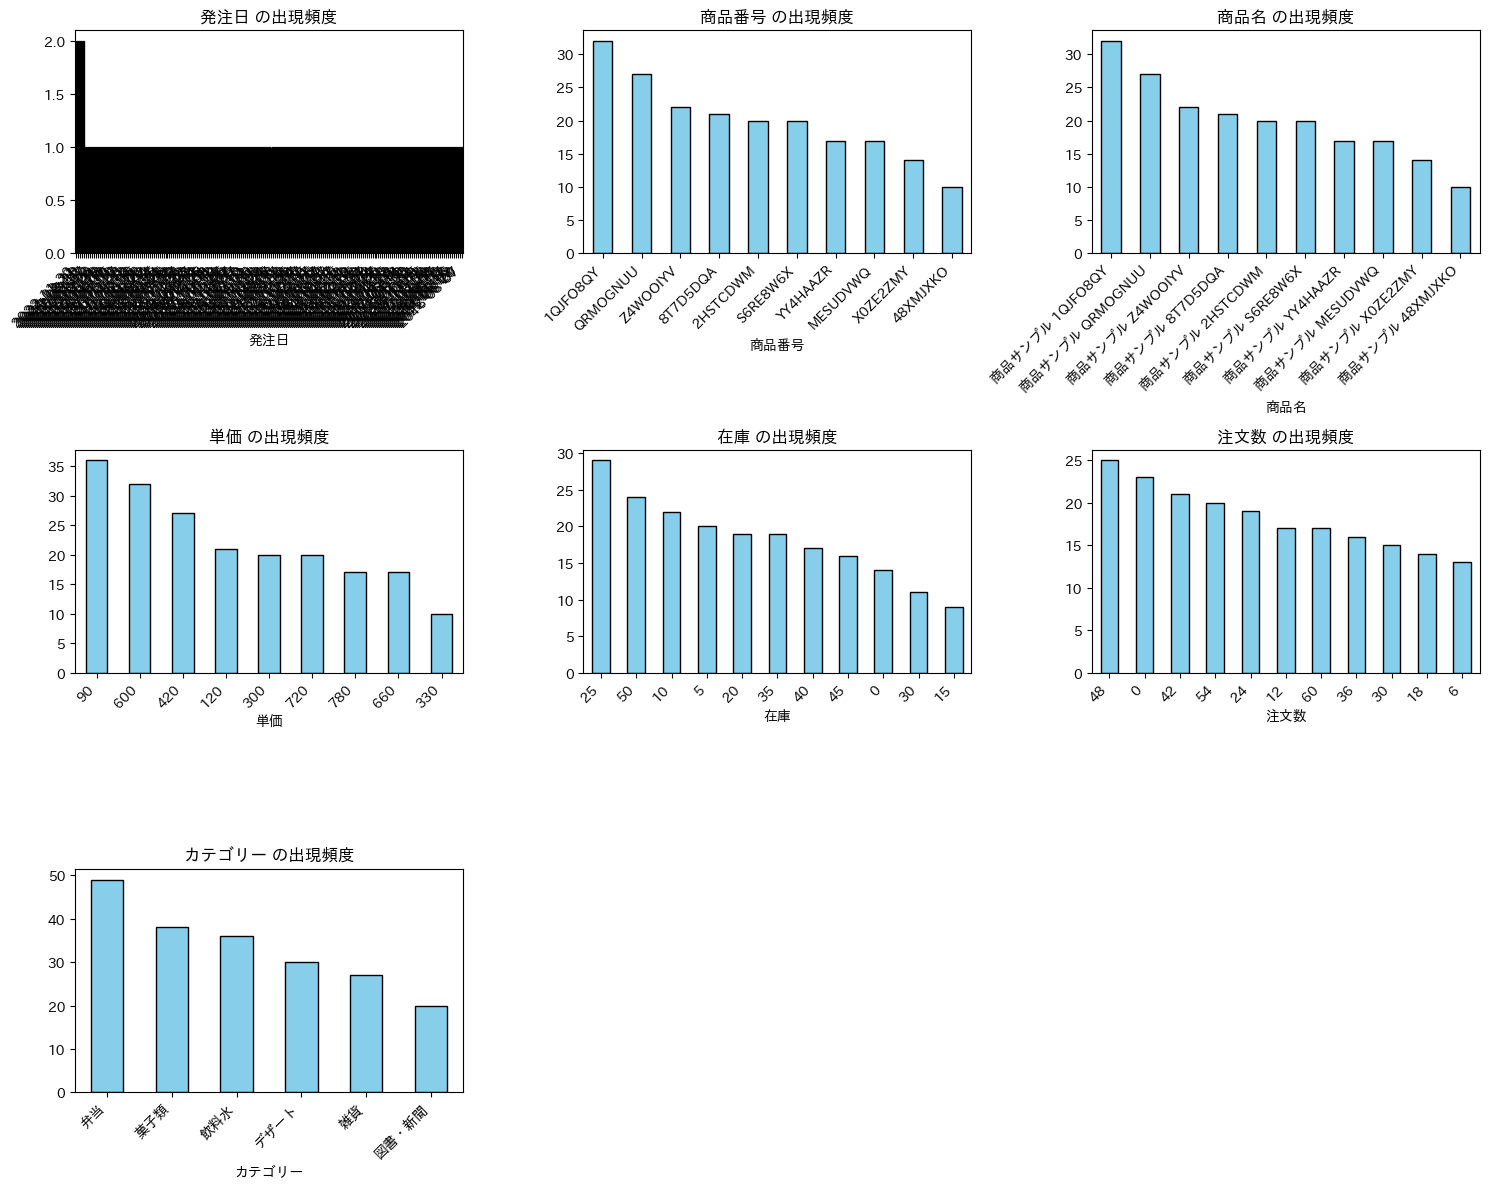

,count,mean,std,min,25%,50%,75%,max
商品番号,,,,,,,,
1QJFO8QY,32.0,35.250000,18.461818,0.0,24.0,36.0,49.5,60.0
2HSTCDWM,20.0,29.400000,21.137146,0.0,12.0,27.0,48.0,60.0
48XMJXKO,10.0,21.600000,13.326665,0.0,13.5,21.0,30.0,42.0
8T7D5DQA,21.0,25.142857,18.260027,0.0,12.0,36.0,42.0,54.0
MESUDVWQ,17.0,43.764706,18.219253,0.0,42.0,48.0,54.0,60.0
QRMOGNUU,27.0,33.111111,16.588535,6.0,21.0,36.0,48.0,60.0
S6RE8W6X,20.0,33.300000,21.631118,0.0,12.0,39.0,54.0,60.0
X0ZE2ZMY,14.0,21.857143,21.901377,0.0,1.5,15.0,39.0,60.0
YY4HAAZR,17.0,31.764706,18.095336,0.0,18.0,30.0,42.0,60.0


In [20]:
import numpy as np
import matplotlib.pyplot as plt
import pandas as pd
import japanize_matplotlib

# csvファイルをデータフレームとして読み込む
df = pd.read_csv("sample_pandas_6.csv")
category_df = pd.read_csv('category.csv')

# 商品番号をキーにしてカテゴリー情報を結合
df = pd.merge(df, category_df[['商品番号', 'カテゴリー']], how='inner', on='商品番号')

# カラム名のリストを取得
column_list = df.columns.tolist()
print("描画するカラム:", column_list)

# 3行3列のサブプロットを作成（カラム数が7つなので、3x3=9マスあれば全て収まります）
fig, axes = plt.subplots(3, 3, figsize=(15, 12), tight_layout=True)

# サブプロットの2次元配列を1次元に平坦化（フラット化）する
flat_axes = axes.flatten()

# 各カラムごとに棒グラフを描画する
for i, column in enumerate(column_list):
    ax = flat_axes[i]
    # 各列のユニークな値の出現回数をカウントして棒グラフを描画
    df[column].value_counts().plot(kind='bar', ax=ax, edgecolor='black', color='skyblue')
    ax.set_title(f'{column} の出現頻度')
    ax.set_xticklabels(ax.get_xticklabels(), rotation=45, ha='right')

# 余ったサブプロット（8個目、9個目の領域）を非表示にする
for j in range(len(column_list), len(flat_axes)):
    flat_axes[j].axis('off')

# グラフを表示
plt.show()

# ある基準列（商品番号列）ごとに要素をグループにまとめサブ列（注文数列）を集計するメソッドと、基本統計量を算出するメソッドを組み合わせたコードを記載する
# データフレームを基準列ごとに要素をグループにまとめ、サブ列を集計するメソッド
# df.groupby('基準列')['サブ列'].集計関数()
# データフレームの基本統計量を算出するメソッド
# df.groupby('基準列')['サブ列'].describe()
df.groupby('商品番号')['注文数'].describe()
